# Calibration

## Importing packages

In [364]:
# Data handling and manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Statistical modeling and optimization
import statsmodels.api as sm
import optbinning as optb
from scipy.stats import chi2, binom

# Progress bar utility
from tqdm import tqdm

# HTTP requests for external data sources
import requests

# Metrics
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Serialization and deserialization
import pickle

## Loading data

In [365]:
cali_data = pd.read_csv("Data/pd_modelling.csv")

## Loading model

In [366]:
with open("Pickle/binning_var.pkl", "rb") as f:
    binning = pickle.load(f)

In [367]:
with open("Pickle/model.pkl", "rb") as f:
    model = pickle.load(f)

## Calculating PD and WoE values

In [368]:
woe = []

for var in binning.keys():
    woe.append(pd.Series(binning[var].transform(cali_data[var], metric = "woe"), index=cali_data.index, name="WoE_" + var))

cali_data_woe = pd.concat([cali_data] + woe, axis=1)

In [369]:
vars = model.model.exog_names
cali_data_woe["const"] = 1

cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])

C:\Users\niels\AppData\Local\Temp\ipykernel_20740\515790858.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["const"] = 1
C:\Users\niels\AppData\Local\Temp\ipykernel_20740\515790858.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["uncalibrated_pd"] = model.predict(cali_data_woe[vars])


## Calculating LRA DR

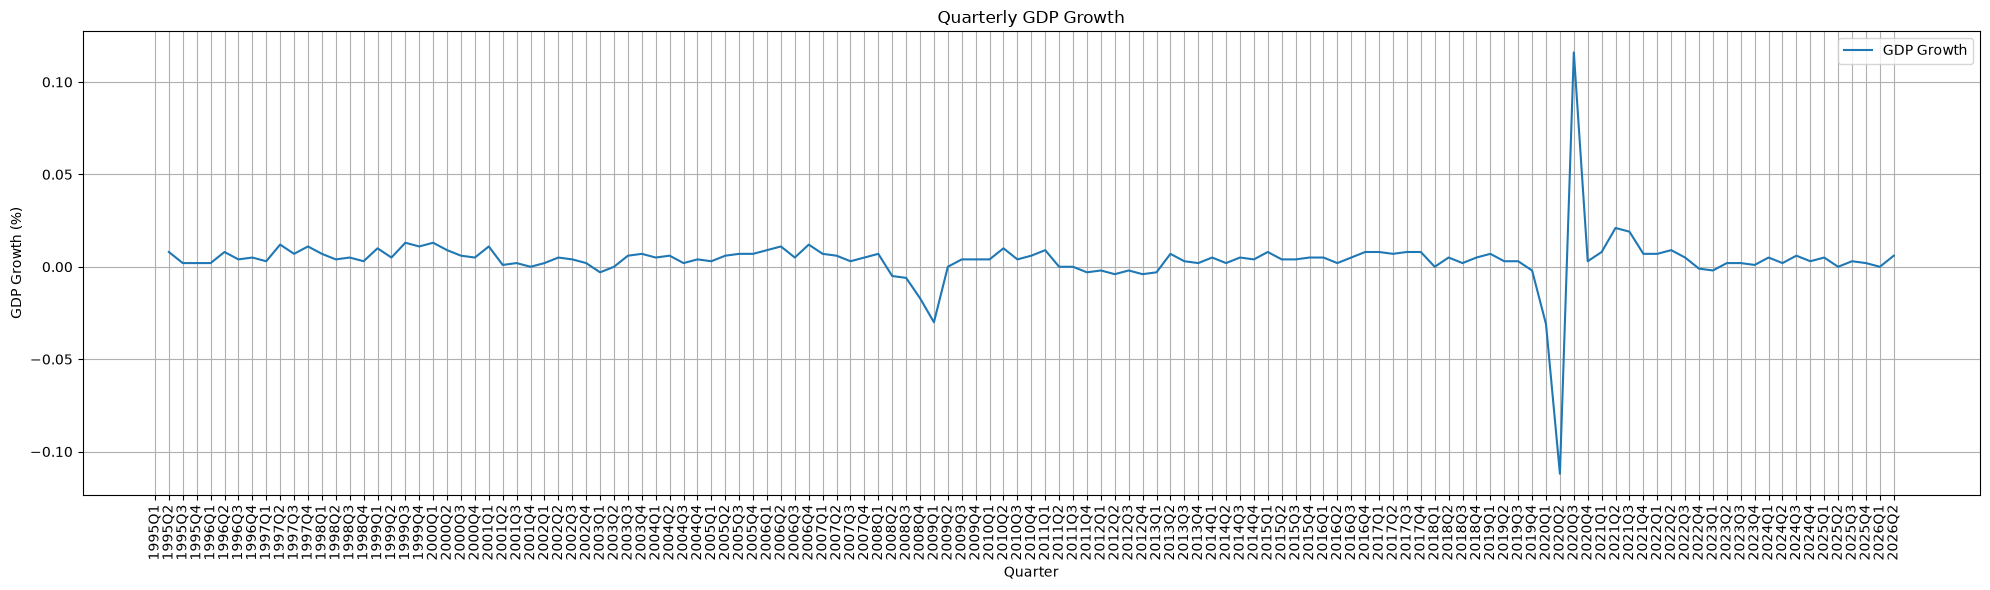

In [370]:
url = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/namq_10_gdp"

params = {
    "geo": "EA",
    "freq": "Q",
    "na_item": "B1GQ",
    "unit": "CLV_PCH_PRE",
    "s_adj": "SCA",
    "sinceTimePeriod": "1995-Q1"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
data = response.json()

time_index = data["dimension"]["time"]["category"]["index"]

gdp = pd.DataFrame([
    {
        "quarter": quarter,
        "gdp_growth": data["value"].get(str(idx))
    }
    for quarter, idx in sorted(time_index.items(), key=lambda x: x[1])
])

quarter = lambda x: pd.Period(x, freq='Q')
gdp["quarter"] = gdp["quarter"].apply(quarter).astype(str)
gdp["gdp_growth"] = gdp["gdp_growth"]/100

plt.figure(figsize=(20, 6))
plt.plot(gdp["quarter"], gdp["gdp_growth"], label="GDP Growth")
plt.xlabel("Quarter")
plt.ylabel("GDP Growth (%)")
plt.title("Quarterly GDP Growth")
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [371]:
dr = cali_data_woe.groupby("quarter")[["default_12m", "uncalibrated_pd"]].mean()
dr = dr.reset_index()

In [372]:
dr = dr.merge(gdp, on="quarter", how="outer")

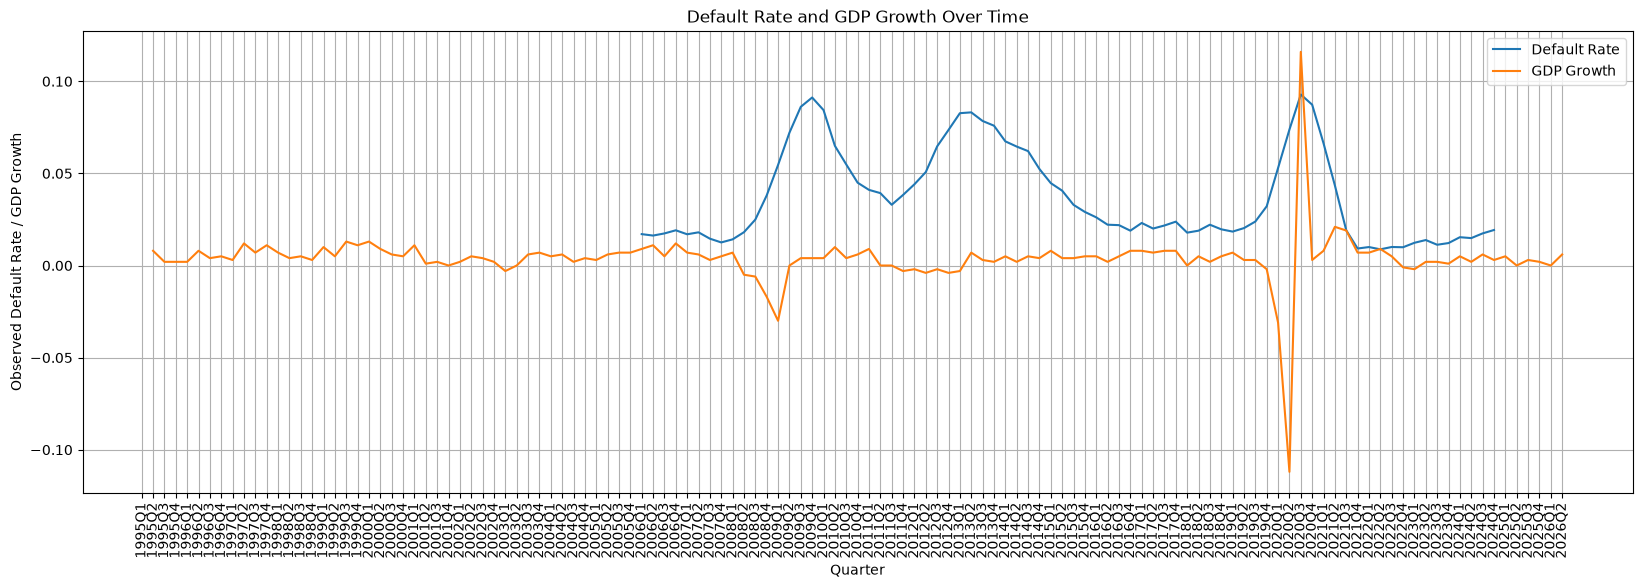

In [373]:
plt.figure(figsize=(20, 6))
plt.plot(dr["quarter"], dr["default_12m"])
plt.plot(dr["quarter"], dr["gdp_growth"])
plt.legend(["Default Rate", "GDP Growth"])
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / GDP Growth")
plt.title("Default Rate and GDP Growth Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

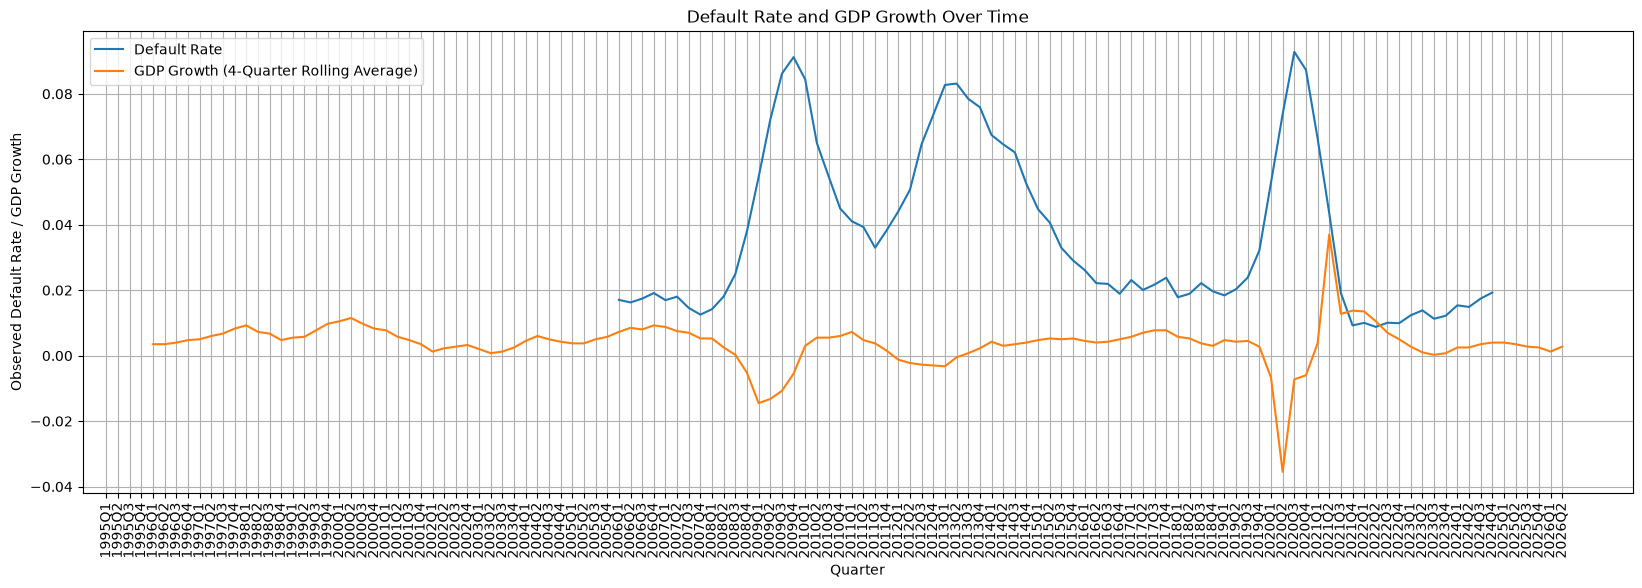

In [374]:
plt.figure(figsize=(20, 6))
plt.plot(dr["quarter"], dr["default_12m"])
plt.plot(dr["quarter"], dr["gdp_growth"].rolling(window=4).mean())
plt.legend(["Default Rate", "GDP Growth (4-Quarter Rolling Average)"])
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / GDP Growth")
plt.title("Default Rate and GDP Growth Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

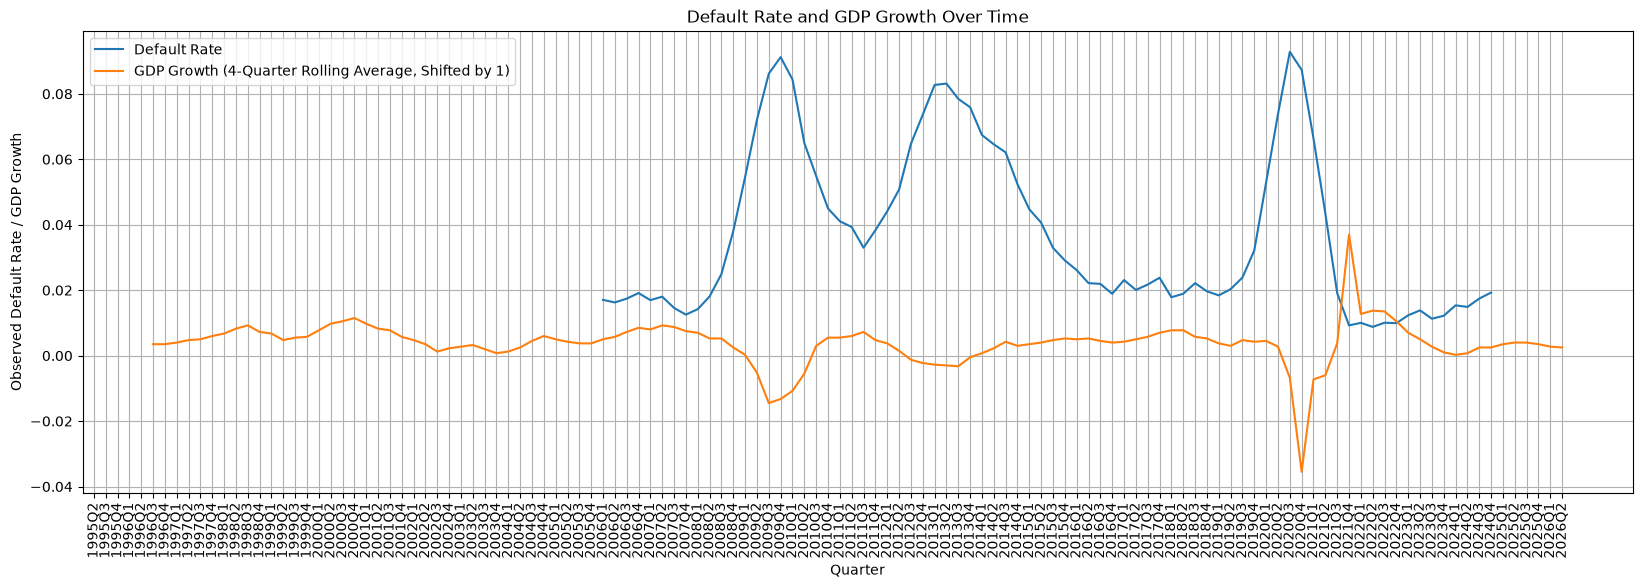

In [375]:
plt.figure(figsize=(20, 6))
plt.plot(dr["quarter"], dr["default_12m"])
plt.plot(dr["quarter"], dr["gdp_growth"].rolling(window=4).mean().shift(2))
plt.legend(["Default Rate", "GDP Growth (4-Quarter Rolling Average, Shifted by 1)"])
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / GDP Growth")
plt.title("Default Rate and GDP Growth Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

In [376]:
dr["gdp_growth_4q_shifted_2"] = dr["gdp_growth"].rolling(window=4).mean().shift(2)

In [377]:
X = dr[["gdp_growth_4q_shifted_2", "default_12m"]].copy()
X.dropna(inplace=True)
X.sort_values(by="gdp_growth_4q_shifted_2", inplace=True)
X = sm.add_constant(X, has_constant='add')

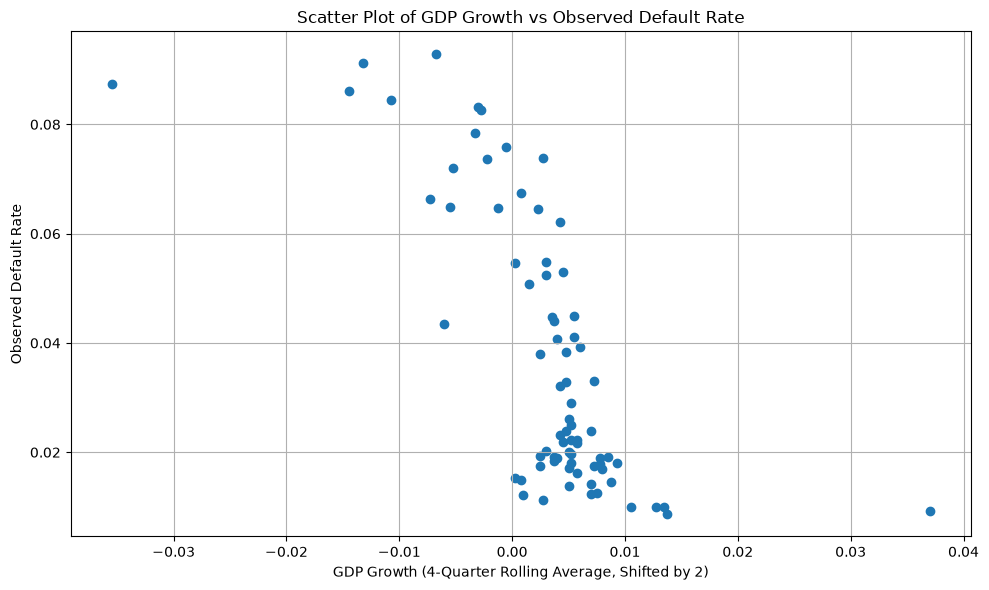

In [378]:
plt.figure(figsize=(10, 6))
plt.scatter(dr["gdp_growth_4q_shifted_2"], dr["default_12m"])
plt.xlabel("GDP Growth (4-Quarter Rolling Average, Shifted by 2)")
plt.ylabel("Observed Default Rate")
plt.title("Scatter Plot of GDP Growth vs Observed Default Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

In [379]:
X = X[(X["gdp_growth_4q_shifted_2"]<0.03) & (X["gdp_growth_4q_shifted_2"]>-0.03)].copy()

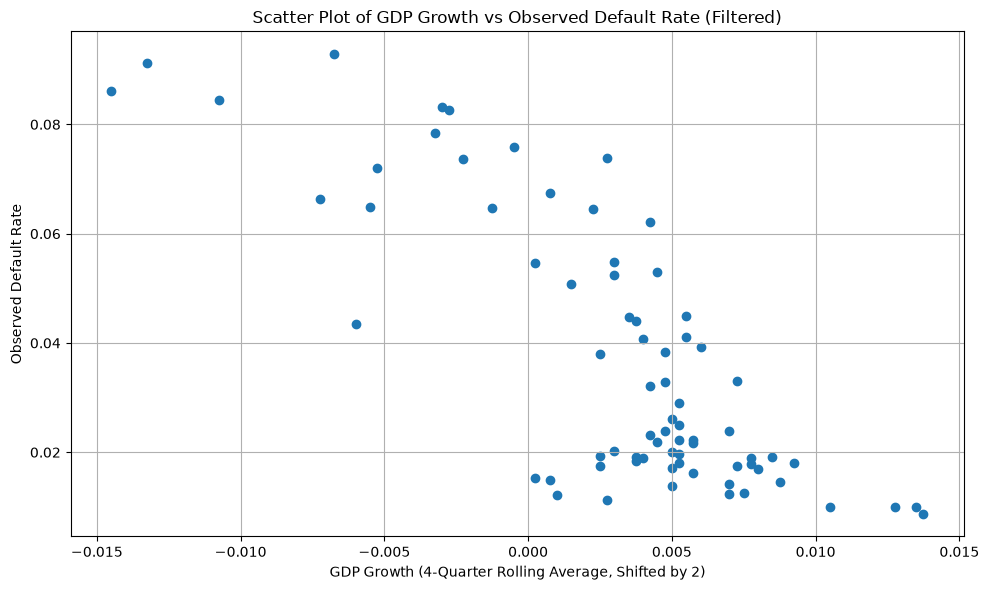

In [380]:
plt.figure(figsize=(10, 6))
plt.scatter(X["gdp_growth_4q_shifted_2"], X["default_12m"])
plt.xlabel("GDP Growth (4-Quarter Rolling Average, Shifted by 2)")
plt.ylabel("Observed Default Rate")
plt.title("Scatter Plot of GDP Growth vs Observed Default Rate (Filtered)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [381]:
X = X[(X["default_12m"] >0.03) | (X["gdp_growth_4q_shifted_2"] > 0.005)].copy()

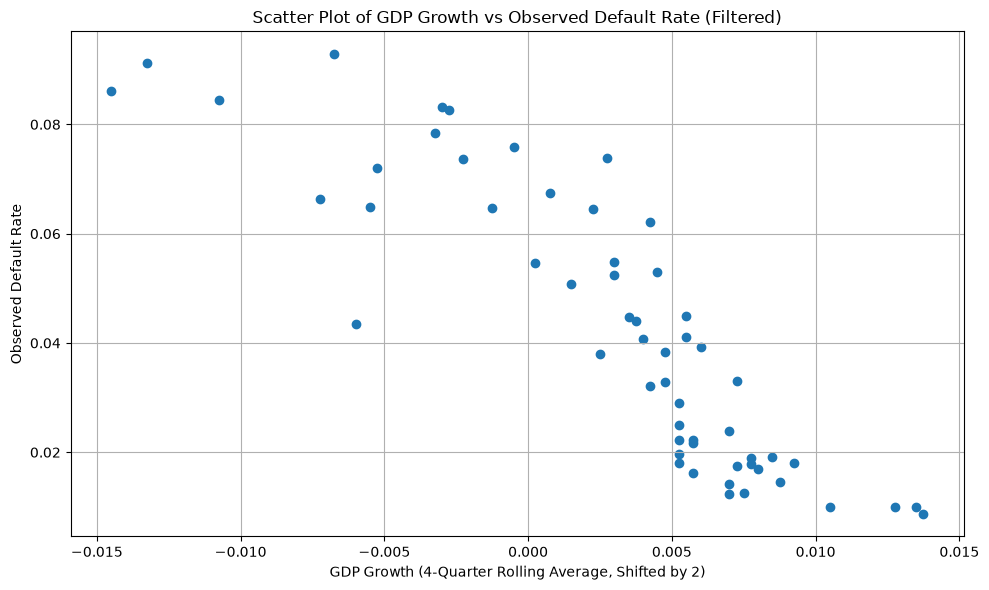

In [382]:
plt.figure(figsize=(10, 6))
plt.scatter(X["gdp_growth_4q_shifted_2"], X["default_12m"])
plt.xlabel("GDP Growth (4-Quarter Rolling Average, Shifted by 2)")
plt.ylabel("Observed Default Rate")
plt.title("Scatter Plot of GDP Growth vs Observed Default Rate (Filtered)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [383]:
X = X[(X["default_12m"] >0.06) | (X["gdp_growth_4q_shifted_2"] > -0.005)].copy()

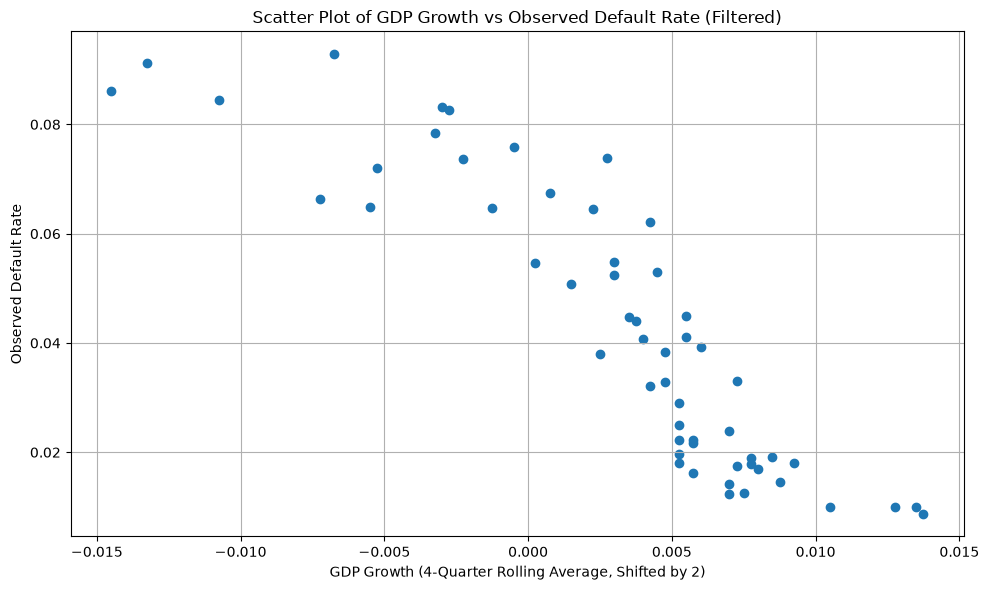

In [384]:
plt.figure(figsize=(10, 6))
plt.scatter(X["gdp_growth_4q_shifted_2"], X["default_12m"])
plt.xlabel("GDP Growth (4-Quarter Rolling Average, Shifted by 2)")
plt.ylabel("Observed Default Rate")
plt.title("Scatter Plot of GDP Growth vs Observed Default Rate (Filtered)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [385]:
X["max(gdp_growth_4q_shifted_2-0.001, 0)"] = X["gdp_growth_4q_shifted_2"].apply(lambda x: max(x-0.001, 0))
X["max(gdp_growth_4q_shifted_2-0.007, 0)"] = X["gdp_growth_4q_shifted_2"].apply(lambda x: max(x-0.007, 0))

In [386]:
y = X["default_12m"].copy()
X.drop(columns=["default_12m"], inplace=True)

In [387]:
macroreg = sm.OLS(endog=y, exog=X)
macroreg = macroreg.fit(disp=0)
print(macroreg.summary())

                            OLS Regression Results                            
Dep. Variable:            default_12m   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.872
Method:                 Least Squares   F-statistic:                     125.5
Date:                 ti, 20 okt 2026   Prob (F-statistic):           8.41e-24
Time:                        23:58:57   Log-Likelihood:                 185.19
No. Observations:                  56   AIC:                            -362.4
Df Residuals:                      52   BIC:                            -354.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

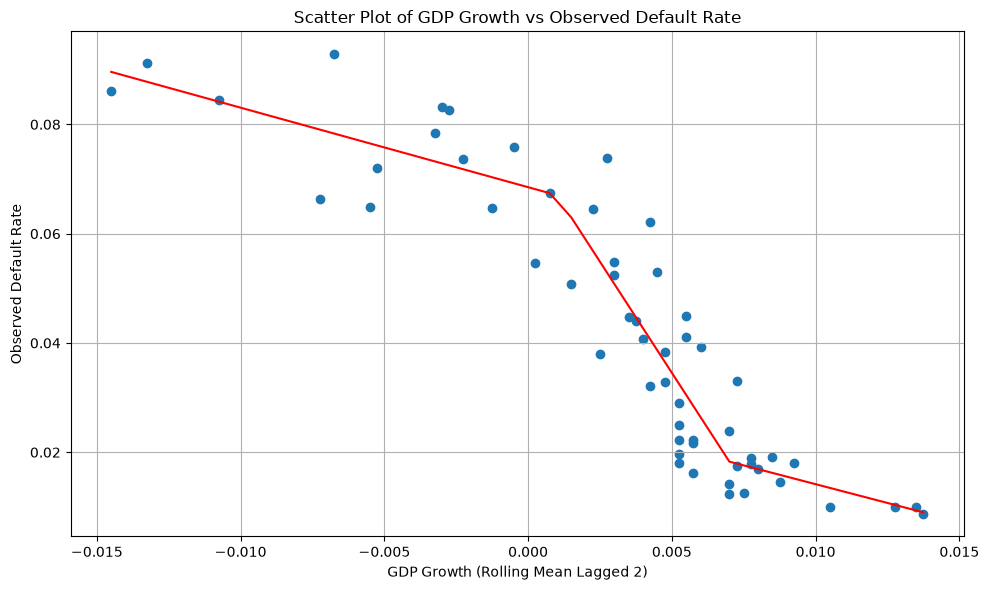

In [388]:
plt.figure(figsize=(10, 6))
plt.scatter(X["gdp_growth_4q_shifted_2"], y)
plt.plot(X["gdp_growth_4q_shifted_2"], macroreg.fittedvalues, color='red')
plt.xlabel("GDP Growth (Rolling Mean Lagged 2)")
plt.ylabel("Observed Default Rate")
plt.title("Scatter Plot of GDP Growth vs Observed Default Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

In [389]:
dr["const"] = 1
dr["max(gdp_growth_4q_shifted_2-0.001, 0)"] = dr["gdp_growth_4q_shifted_2"].apply(lambda x: max(x-0.001, 0))
dr["max(gdp_growth_4q_shifted_2-0.007, 0)"] = dr["gdp_growth_4q_shifted_2"].apply(lambda x: max(x-0.007, 0))

In [390]:
dr["macro_dr"] = macroreg.predict(dr[["const", "gdp_growth_4q_shifted_2", "max(gdp_growth_4q_shifted_2-0.001, 0)", "max(gdp_growth_4q_shifted_2-0.007, 0)"]])

In [391]:
test_data = dr[["quarter", "default_12m", "macro_dr"]].copy()
test_data.dropna(inplace=True)

In [392]:
test_data

,quarter,default_12m,macro_dr
44,2006Q1,0.017037,0.034538
45,2006Q2,0.016260,0.028441
46,2006Q3,0.017422,0.017937
47,2006Q4,0.019122,0.016219
48,2007Q1,0.016961,0.016906
...,...,...,...
115,2023Q4,0.012186,0.067052
116,2024Q1,0.015373,0.068144
117,2024Q2,0.014881,0.067416
118,2024Q3,0.017437,0.054859


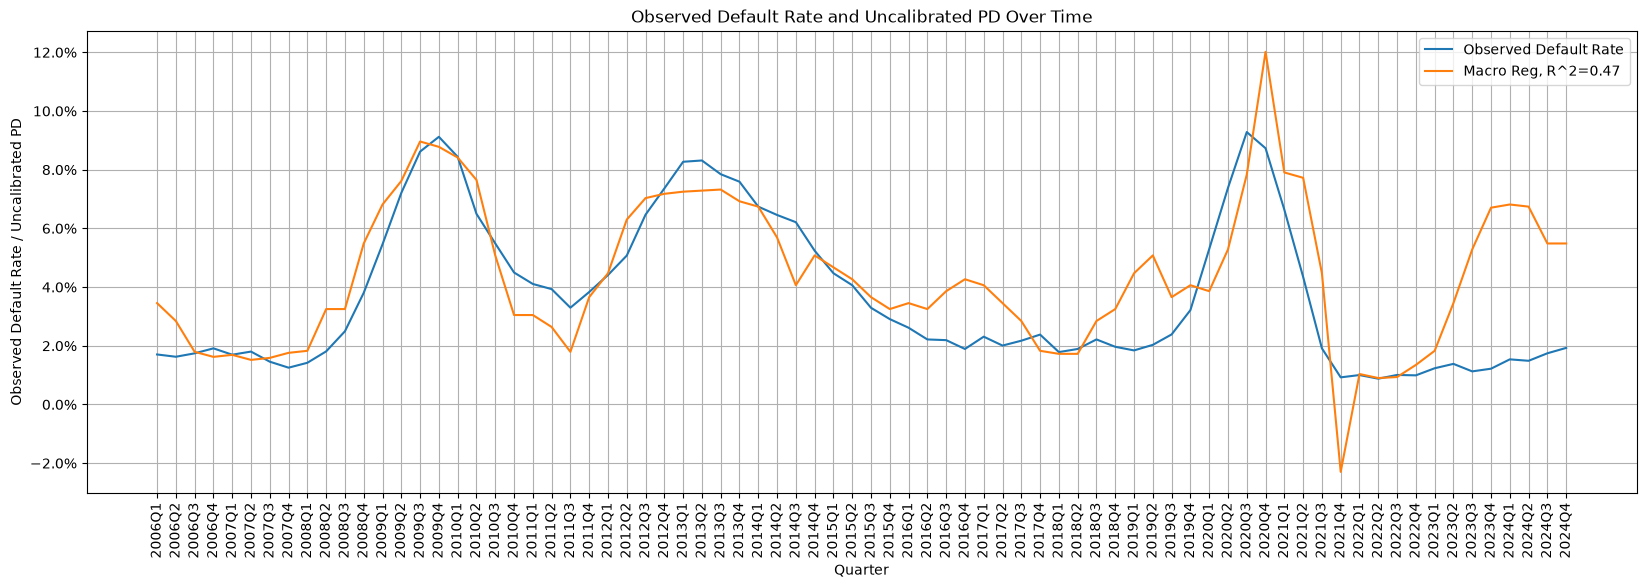

In [393]:
r2 = 1-np.sum((test_data["default_12m"]-test_data["macro_dr"])**2)/np.sum((test_data["default_12m"]-np.mean(test_data["default_12m"]))**2)

plt.figure(figsize=(20, 6))
plt.plot(test_data["quarter"], test_data["default_12m"], label="Observed Default Rate")
plt.plot(test_data["quarter"], test_data["macro_dr"], label=f"Macro Reg, R^2={r2:.2f}")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [394]:
dr_na = dr["default_12m"].isna().astype(int)
dr_24q4 = (dr["quarter"] <= "2024Q4").astype(int)

dr["dr"] = np.where(dr_na == 1, dr["macro_dr"], dr["default_12m"])
dr["dr"] = np.where(dr_24q4 == 0, np.nan, dr["dr"])

In [395]:
lra_dr = np.mean(dr["dr"])

In [398]:
dr.head(10)

,quarter,default_12m,uncalibrated_pd,gdp_growth,gdp_growth_4q_shifted_2,const,"max(gdp_growth_4q_shifted_2-0.001, 0)","max(gdp_growth_4q_shifted_2-0.007, 0)",macro_dr,dr
0,1995Q1,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN
1,1995Q2,NaN,NaN,0.008,NaN,1,NaN,NaN,NaN,NaN
2,1995Q3,NaN,NaN,0.002,NaN,1,NaN,NaN,NaN,NaN
3,1995Q4,NaN,NaN,0.002,NaN,1,NaN,NaN,NaN,NaN
4,1996Q1,NaN,NaN,0.002,NaN,1,NaN,NaN,NaN,NaN
5,1996Q2,NaN,NaN,0.008,NaN,1,NaN,NaN,NaN,NaN
6,1996Q3,NaN,NaN,0.004,0.00350,1,0.00250,0.0,0.046731,0.046731
7,1996Q4,NaN,NaN,0.005,0.00350,1,0.00250,0.0,0.046731,0.046731
8,1997Q1,NaN,NaN,0.003,0.00400,1,0.00300,0.0,0.042666,0.042666
9,1997Q2,NaN,NaN,0.012,0.00475,1,0.00375,0.0,0.036570,0.036570


In [ ]:
dr = dr[(dr["quarter"] > "1996Q2")].copy()

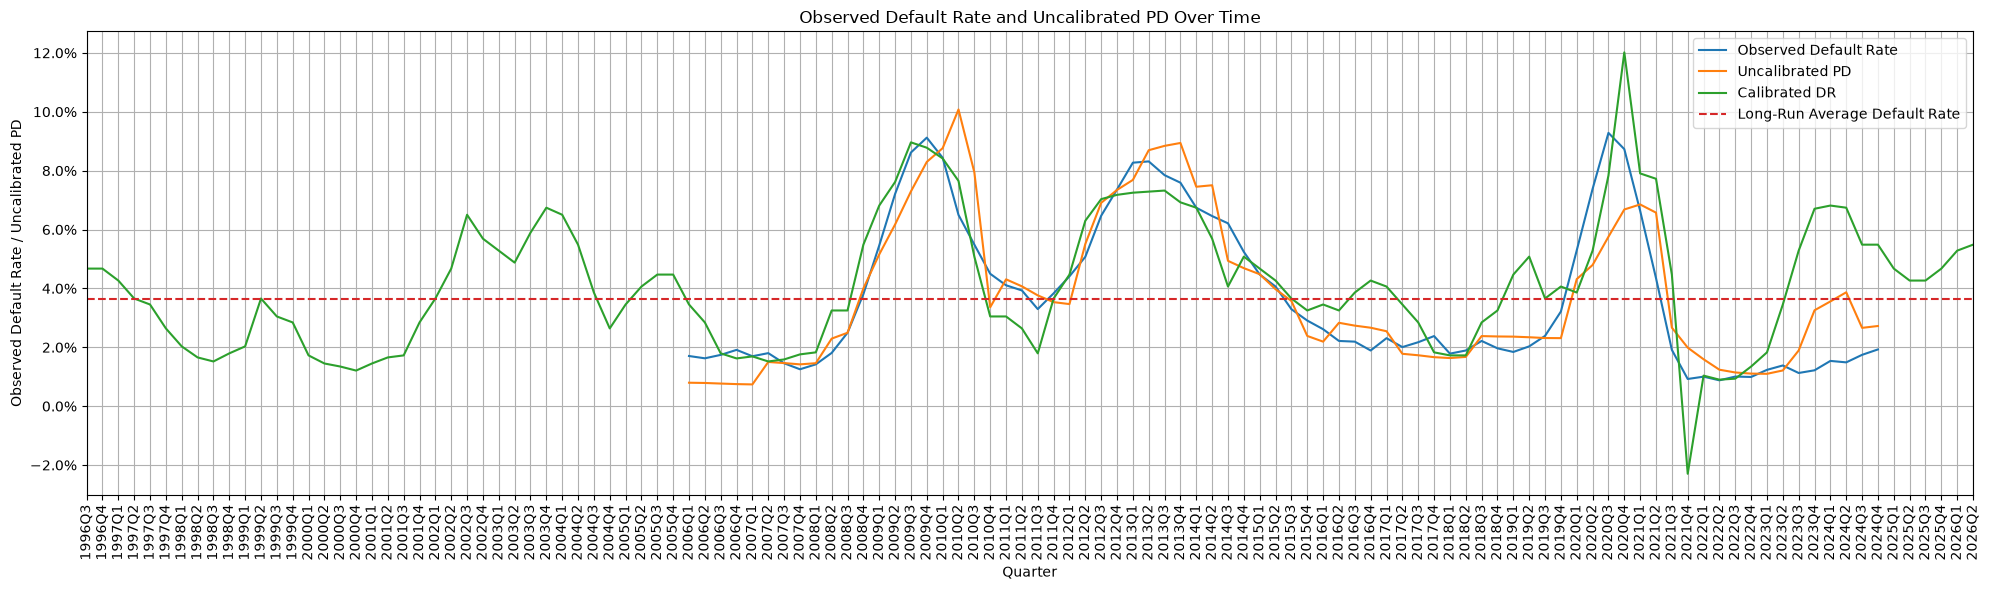

In [403]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.plot(dr.index, dr["macro_dr"], label="Calibrated DR")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(ticks = dr.index, rotation=90, labels=dr["quarter"])
plt.plot(dr.index, [lra_dr]*len(dr.index), label="Long-Run Average Default Rate", linestyle="--")
#plt.plot(dr.index, [np.mean(dr["default_12m"])]*len(dr.index), label="Avg. ODR")
plt.xlim(dr.index.min(), dr.index.max())
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.tight_layout()
plt.show()

In [11]:
def adjustment_score(pds, target):
    logodds = np.log(pds / (1 - pds))
    
    def sigmoid(x):
        return 1 / (1 + np.exp(-x))

    def f(k):
        return np.mean(sigmoid(logodds + k)) - target
    
    def derivative(k):
        s = sigmoid(logodds + k)
        return np.mean(s * (1 - s))

    # Use Newton-Raphson method to find the root of f(k)
    k = 0.0
    for _ in range(100):
        fk = f(k)
        if abs(fk) < 1e-8:
            break
        k -= fk / derivative(k)
    return k


In [12]:
adjustment_quarter = (cali_data_woe["quarter"] == "2024Q4")  # Example quarter, replace with the desired one

k = adjustment_score(cali_data_woe[adjustment_quarter]["uncalibrated_pd"], target = lra_dr)

In [13]:
cali_data_woe["pd"] = 1 / (1 + np.exp(-(np.log(cali_data_woe["uncalibrated_pd"] / (1 - cali_data_woe["uncalibrated_pd"])) + k)))

C:\Users\niels\AppData\Local\Temp\ipykernel_20740\3226258103.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cali_data_woe["pd"] = 1 / (1 + np.exp(-(np.log(cali_data_woe["uncalibrated_pd"] / (1 - cali_data_woe["uncalibrated_pd"])) + k)))


In [14]:
edr = cali_data_woe.groupby("quarter")["pd"].mean()

## Adjustment period

In [15]:
adjustment_period = (cali_data_woe["quarter"] >= "2021Q4")  # Example period, replace with the desired one

In [16]:
adjustment_data = cali_data_woe[adjustment_period].copy()

## Curve calibration

In [17]:
cutter = optb.OptimalBinning(name = "uncalibrated_pd", min_bin_size=0.005, monotonic_trend="ascending")
cutter.fit(adjustment_data["uncalibrated_pd"], adjustment_data["default_12m"])

,name,'uncalibrated_pd'
,min_bin_size,0.005
,monotonic_trend,'ascending'
,dtype,'numerical'
,prebinning_method,'cart'
,solver,'cp'
,divergence,'iv'
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_n_bins,None


In [18]:
cutter.binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.01)",2160,0.121280,2147,13,0.006019,0.748176,0.048119,5.878386e-03
1,"[0.01, 0.01)",1968,0.110500,1956,12,0.006098,0.735049,0.042558,5.203103e-03
2,"[0.01, 0.02)",8101,0.454857,8001,100,0.012344,0.02345,0.000247,3.091173e-05
3,"[0.02, 0.04)",2865,0.160865,2829,36,0.012565,0.005458,0.000005,5.975309e-07
4,"[0.04, 0.05)",1811,0.101684,1773,38,0.020983,-0.515859,0.035112,4.340923e-03
5,"[0.05, inf)",905,0.050814,879,26,0.028729,-0.838013,0.054948,6.674360e-03
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
Totals,,17810,1.000000,17585,225,0.012633,,0.180989,2.212828e-02


In [19]:
adjustment_data["bin"] = cutter.transform(adjustment_data["uncalibrated_pd"], metric="bins")

In [20]:
grouping = adjustment_data.groupby("bin").agg({
    "uncalibrated_pd": "mean",
    "default_12m": "mean"
})

In [21]:
grouping["uncalibrated_score"] = -np.log(grouping["uncalibrated_pd"]/(1-grouping["uncalibrated_pd"]))
grouping["central_score"] = -np.log(grouping["default_12m"]/(1-grouping["default_12m"]))

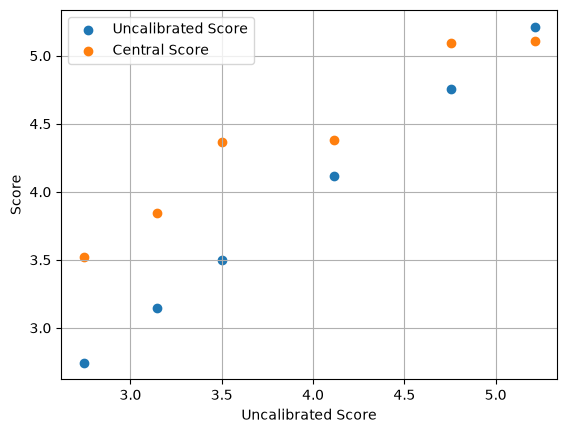

In [22]:
plt.scatter(grouping["uncalibrated_score"], grouping["uncalibrated_score"], label="Uncalibrated Score")
plt.scatter(grouping["uncalibrated_score"], grouping["central_score"], label="Central Score")
plt.xlabel("Uncalibrated Score")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
kurve = sm.OLS(endog = grouping["central_score"], exog = sm.add_constant(grouping["uncalibrated_score"])).fit(disp=0)
print(kurve.summary())

                            OLS Regression Results                            
Dep. Variable:          central_score   R-squared:                       0.935
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     57.85
Date:                Tue, 20 Oct 2026   Prob (F-statistic):            0.00160
Time:                        21:26:43   Log-Likelihood:                 2.9015
No. Observations:                   6   AIC:                            -1.803
Df Residuals:                       4   BIC:                            -2.220
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  1.8419      0

c:\Users\niels\Documents\PD-modelling\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


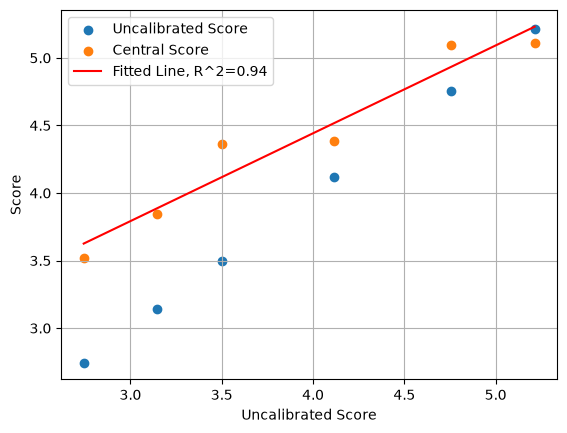

In [51]:
plt.scatter(grouping["uncalibrated_score"], grouping["uncalibrated_score"], label="Uncalibrated Score")
plt.scatter(grouping["uncalibrated_score"], grouping["central_score"], label="Central Score")
plt.plot(grouping["uncalibrated_score"], kurve.fittedvalues, color="red", label=f"Fitted Line, R^2={kurve.rsquared:.2f}")
plt.xlabel("Uncalibrated Score")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

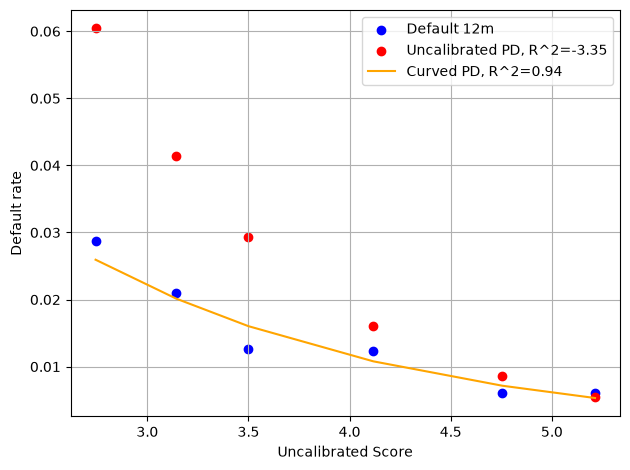

In [50]:
grouping["curved_score"] = kurve.predict(sm.add_constant(grouping["uncalibrated_score"], has_constant='add'))
grouping["curved_pd"] = 1/(1+np.exp(grouping["curved_score"]))

plt.scatter(grouping["uncalibrated_score"], grouping["default_12m"], color='blue', label='Default 12m')
plt.scatter(grouping["uncalibrated_score"], grouping["uncalibrated_pd"], color='red', label=f'Uncalibrated PD, R^2={1-np.sum((grouping["default_12m"]-grouping["uncalibrated_pd"])**2)/np.sum((grouping["default_12m"]-np.mean(grouping["default_12m"]))**2):.2f}')
plt.plot(grouping["uncalibrated_score"], grouping["curved_pd"], color='orange', label=f'Curved PD, R^2={1-np.sum((grouping["default_12m"]-grouping["curved_pd"])**2)/np.sum((grouping["default_12m"]-np.mean(grouping["default_12m"]))**2):.2f}')
plt.legend(loc='best')
plt.grid(True)
plt.xlabel("Uncalibrated Score")
plt.ylabel("Default rate")
plt.tight_layout()
plt.show()

In [52]:
cali_data_woe["uncalibrated_score"] = -np.log(cali_data_woe["uncalibrated_pd"]/(1-cali_data_woe["uncalibrated_pd"]))

In [53]:
cali_data_woe["curved_score"] = kurve.predict(sm.add_constant(cali_data_woe["uncalibrated_score"]))

In [54]:
cali_data_woe["curved_pd"] = 1 / (1 + np.exp(cali_data_woe["curved_score"]))

In [55]:
k = adjustment_score(cali_data_woe[adjustment_period]["curved_pd"], lra_dr)

In [56]:
cali_data_woe["adjusted_curved_pd"] = 1 / (1 + np.exp((cali_data_woe["curved_score"] - k)))

In [57]:
edr = cali_data_woe.groupby("quarter")["adjusted_curved_pd"].mean()

In [58]:
lra_dr

np.float64(0.037249380279295294)

In [59]:
np.mean(cali_data_woe[adjustment_period]["adjusted_curved_pd"])

np.float64(0.03724938432800849)

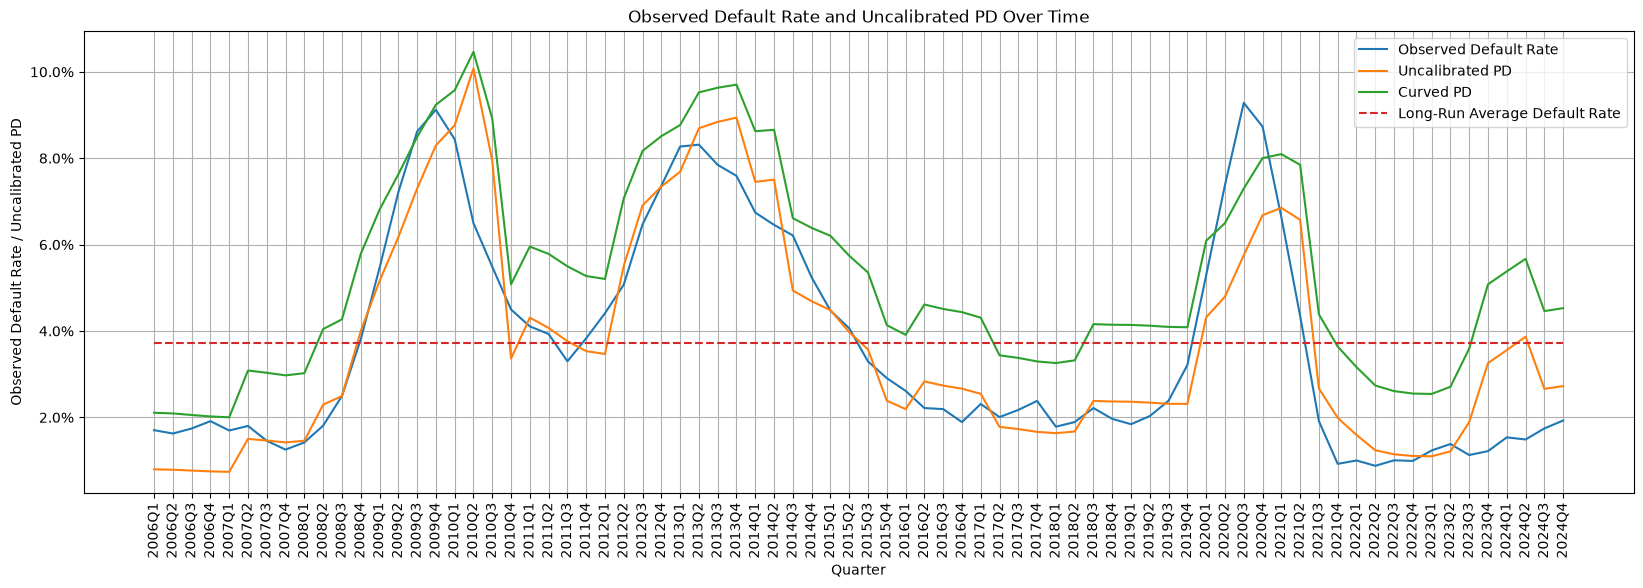

In [62]:
plt.figure(figsize=(20, 6))
plt.plot(dr.index, dr["default_12m"], label="Observed Default Rate")
plt.plot(dr.index, dr["uncalibrated_pd"], label="Uncalibrated PD")
plt.plot(edr, label="Curved PD")
plt.xlabel("Quarter")
plt.ylabel("Observed Default Rate / Uncalibrated PD")
plt.title("Observed Default Rate and Uncalibrated PD Over Time")
plt.xticks(rotation=90)
plt.plot(dr.index, [lra_dr]*len(dr.index), label="Long-Run Average Default Rate", linestyle="--")
plt.grid(True)
plt.legend(loc = 'best')
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax = 1, decimals = 1))
plt.show()

In [64]:
import requests
import pandas as pd

url = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/namq_10_gdp"

params = {
    "geo": "EA",
    "freq": "Q",
    "na_item": "B1GQ",
    "unit": "CLV_PCH_PRE",
    "s_adj": "SCA",
    "sinceTimePeriod": "1995-Q1"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
data = response.json()

time_index = data["dimension"]["time"]["category"]["index"]

df = pd.DataFrame([
    {
        "quarter": quarter,
        "gdp_growth": data["value"].get(str(idx))
    }
    for quarter, idx in sorted(time_index.items(), key=lambda x: x[1])
])

print(df.tail(10))

     quarter  gdp_growth
116  2024-Q1         0.5
117  2024-Q2         0.2
118  2024-Q3         0.6
119  2024-Q4         0.3
120  2025-Q1         0.5
121  2025-Q2         0.0
122  2025-Q3         0.3
123  2025-Q4         0.2
124  2026-Q1         0.0
125  2026-Q2         0.6


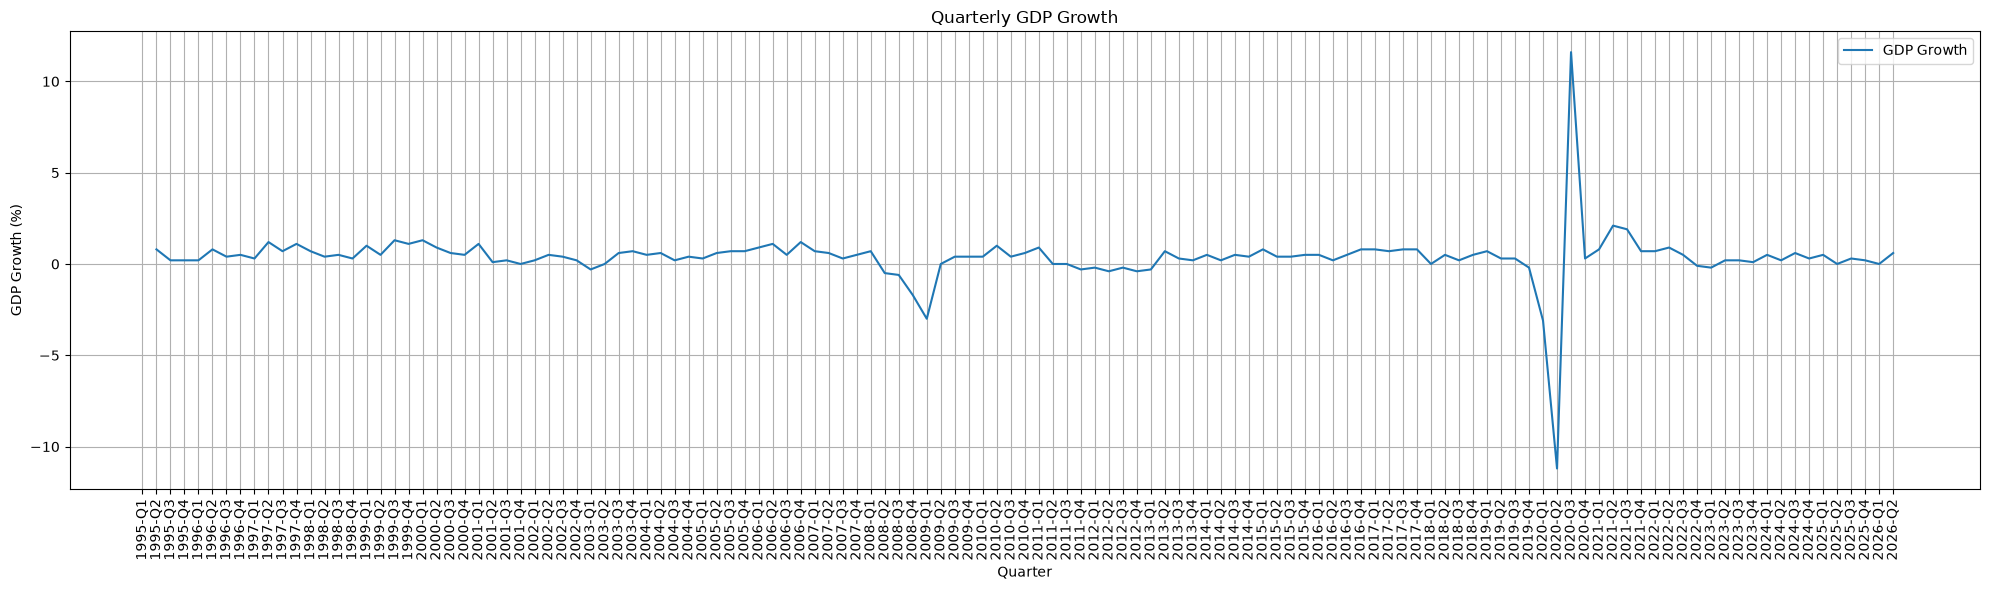

In [67]:
plt.figure(figsize=(20, 6))
plt.plot(df["quarter"], df["gdp_growth"], label="GDP Growth")
plt.xlabel("Quarter")
plt.ylabel("GDP Growth (%)")
plt.title("Quarterly GDP Growth")
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='best')
plt.tight_layout()
plt.show()